# Проектирование ТВД 150 л.с. при πк = 6

Одна ступень турбины компрессора и одна ступень свободной силовой турбины.


# Расчёт цикла двигателя

### Прототипы:
- tj100
- ТВД150 МКБ «Гранит»
- Honeywell TPE331

## 1. Импорт библиотек, исходные данные

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

#-------------------------------------------
pd.set_option('display.max_rows', None)      #чтобы было видно все строки в pandas
pd.set_option('display.max_columns', None)
# Десятичный вывод с 4 знаками после точки; точность вычислений сохраняется.
pd.set_option('display.float_format', '{:.4f}'.format)
#-------------------------------------------

# Мощность двигателя
power_hp = 150.0
HP_TO_KW = 0.73549875
power_kw = power_hp * HP_TO_KW

# Наружные условия
T_a = 288.0          # K
p_a = 101.3          # кПа
velocity = 0.0       # м/с

# Температура газа перед турбиной
T_g = 1250.0         # K

# КПД и потери
eta_k_poly = 0.86    # п кпд цбк по методичке 0.85..0.87
eta_gg_poly = 0.90   # п кпд газогенератора
eta_pt_poly = 0.90   # п кпд силовой турбины

sigma_in = 0.985
sigma_burn = 0.965
eta_burn = 0.98

eta_m_gg = 0.99
eta_m_pt = 0.99

# КПД редуктора:
eta_red = 0.98

# Отборы воздуха
g_leak = 0.005
g_cool = 0.0

# Топливо и газовые постоянные
Q_lhv = 43000.0      # кДж/кг
l0 = 14.61
T_ref = 288.0        # K
R_air = 0.287        # кДж/(кг К)
R_gas = 0.288        # кДж/(кг К)

# Сопло и выход из свободной турбины
pi_nozzle_static = 1.04
c_pt_exit = 250.0    # м/с
phi_nozzle = 0.95
beta_prop = 15.0     # Н/кВт
eta_prop = 0.82

# Настройки вариантного расчёта
n_variants = 801

KCAL_TO_KJ = 4.187

print(f"Мощность на валу: {power_hp:.0f} л.с. = {power_kw:.3f} кВт")

Мощность на валу: 150 л.с. = 110.325 кВт


## 2. Теплофизические свойства

Формулы теплоёмкостей взяты из приложения 6 методички. Для воздуха используется предел alpha → infty

**Формулы следующей ячейки: теплофизические свойства и деление пополам**

Обозначения: $T$ — К, $\alpha$ — коэффициент избытка воздуха, $a=1/\alpha$; для воздуха $a=0$. Теплоёмкости — **кДж/(кг·К)**. В коде `cp_i` — истинная, `cp_m` — средняя теплоёмкость.

Вспомогательные полиномы температуры:

$$U=2.5\cdot10^{-3}T-0.875,\qquad V=2.5\cdot10^{-5}T^2-0.0275T+6.5625,$$
$$W=1.176\cdot10^{-3}T-0.88235,\qquad Z=5.5556\cdot10^{-6}T^2-0.013056T+6.67.$$

$$c_{pi}(T,\alpha)=4.187\begin{cases}
0.0174a+0.2407+(0.0093a+0.0193)U+\left(0.002-\dfrac{0.001056a}{1-0.2a}\right)V,&T<750,\\[2mm]
0.0267a+0.26+(0.0133a+0.032)W-\left(0.00374+\dfrac{0.0094a^2}{1+10a^2}\right)Z,&T\ge750.
\end{cases}$$

$$
c_{pm}(T,\alpha)=4.187\begin{cases}
\dfrac{2.25a+1.2}{10^5}(T-70)+0.236,&T<700,\\
\dfrac{1.25a+2.2}{10^5}(T+450)+0.218,&T\ge700.
\end{cases}
$$

Функции энтальпии записаны **точно как в существующем коде**:

$$h(T,\alpha)=c_{pm}(T,\alpha)T,\qquad
\Delta h(T,\alpha)=h(T,\alpha)-h(T_{ref},\alpha).$$

`process_properties` использует приближение:

$$T_m=\frac{T_1+T_2}{2},\qquad c_p=c_{pi}(T_m,\alpha),\qquad k=\frac{c_p}{c_p-R}.$$

В `bisect` решается $F(x)=0$: $m=(l+r)/2$; если $F(l)F(m)\le0$, заменяем $r=m$, иначе $l=m$. После 80 шагов возвращается $(l+r)/2$. Это выбранный численный алгоритм, не отдельная физическая формула.

**Источник:** «цикл.pdf», приложение 6, с. 56–57; согласование свойств процесса — §2.3, с. 16. Определения `h`, `dh` и правила осреднения показаны здесь для объяснения уже имеющегося кода, без изменения его модели.


In [2]:
def cp_i(T, alpha=np.inf):
    if np.isinf(alpha):
        a = 0.0
    else:
        a = 1.0 / alpha

    if T < 750.0:
        value = ((0.0174*a + 0.2407)
                 + (0.0093*a + 0.0193)*(2.5e-3*T - 0.875)
                 + (2.0e-3 - 1.056e-3*a/(1.0 - 0.2*a))
                 * (2.5e-5*T*T - 0.0275*T + 6.5625))
    else:
        value = ((0.0267*a + 0.26)
                 + (0.0133*a + 0.032)*(1.176e-3*T - 0.88235)
                 - (0.374e-2 + 0.94e-2*a*a/(1.0 + 10*a*a))
                 * (5.5556e-6*T*T - 1.3056e-2*T + 6.67))

    return KCAL_TO_KJ * value


def cp_m(T, alpha=np.inf):
    a = 0.0 if np.isinf(alpha) else 1.0 / alpha

    if T < 700.0:
        value = (2.25*a + 1.2)/1e5*(T - 70.0) + 0.236
    else:
        value = (1.25*a + 2.2)/1e5*(T + 450.0) + 0.218

    return KCAL_TO_KJ * value


def h(T, alpha=np.inf):
    return cp_m(T, alpha) * T


def dh(T, alpha):
    return h(T, alpha) - h(T_ref, alpha)


def process_properties(T1, T2, alpha, R):
    T_mean = (T1 + T2) / 2
    cp = cp_i(T_mean, alpha)
    k = cp / (cp - R)
    return cp, k


def bisect(fun, left, right, n=80):
    f_left = fun(left)

    for _ in range(n):
        middle = (left + right) / 2
        f_middle = fun(middle)

        if f_left * f_middle <= 0:
            right = middle
        else:
            left = middle
            f_left = f_middle

    return (left + right) / 2

## 3. Входное устройство

**Формулы следующей функции `inlet()`**

$T_a,p_a,V$ — статические параметры атмосферы и скорость полёта. Индекс 2 — вход компрессора; возвращаемые $T_2,p_2$ — **полные** параметры.

$$c_p=c_{pi}\left(\frac{T_a+T_2}{2},\infty\right),\qquad k=\frac{c_p}{c_p-R_a},$$
$$c_p(T_2-T_a)=\frac{V^2}{2000},\qquad
M=\frac{V}{\sqrt{1000kR_aT_a}},$$
$$\pi_V=\left(\frac{T_2}{T_a}\right)^{k/(k-1)},\qquad
p_2=p_a\pi_V\sigma_{in}.$$

$T_2$ находится делением пополам. Числа 1000 и 2000 связаны с использованием кДж. При $V=0$: $T_2=T_a$, $\pi_V=1$.

**Источник:** «цикл.pdf», §2.1, с. 10 — полные параметры на входе и коэффициент сохранения давления. Выражения через $V$ — раскрытие перехода от статических к полным параметрам, уже реализованное в исходном ноутбуке.


In [3]:
def inlet():
    def equation(T2):
        cp, k = process_properties(T_a, T2, np.inf, R_air)
        return T2 - T_a - velocity**2/(2000*cp)

    T2 = bisect(equation, T_a, T_a + velocity**2/1000 + 1)
    cp, k = process_properties(T_a, T2, np.inf, R_air)

    M = velocity / math.sqrt(1000*k*R_air*T_a)
    pi_v = (T2/T_a)**(k/(k-1))
    p2 = p_a * pi_v * sigma_in

    return {
        'T2': T2,
        'p2': p2,
        'pi_v': pi_v,
        'M_flight': M,
        'cp_in': cp,
        'k_in': k
    }

## 4. Компрессор

**Формулы следующей функции `compressor()`**

$\pi_k=p_3/p_2$ — степень повышения полного давления; $\eta_{kp}$ — политропический КПД. Свойства определяются по средней температуре $T_m=(T_2+T_3)/2$.

$$c_p=c_{pi}(T_m,\infty),\quad k=\frac{c_p}{c_p-R_a},\quad
T_3=T_2\pi_k^{(k-1)/(k\eta_{kp})},$$
$$\eta_k=\frac{\pi_k^{(k-1)/k}-1}{\pi_k^{(k-1)/(k\eta_{kp})}-1},\qquad
p_3=p_2\pi_k,\qquad L_k=c_p(T_3-T_2).$$

$T_3$ решается неявно, поскольку $c_p$ и $k$ зависят от неё. В коде `expm1(x)` означает $e^x-1$ и сохраняет точность при малом $x$.

**Источник:** «цикл.pdf», с. 9 — переход от политропического КПД к адиабатному; §2.2, с. 11–12 — параметры и работа компрессора. Формула $T_3$ — преобразование этих соотношений.


In [4]:
def compressor(pi_k, inp):
    T2 = inp['T2']

    def equation(T3):
        cp, k = process_properties(T2, T3, np.inf, R_air)
        return T3 - T2*pi_k**((k-1)/(k*eta_k_poly))

    T3 = bisect(equation, T2, T_g)
    cp, k = process_properties(T2, T3, np.inf, R_air)

    x = (k-1)/k * math.log(pi_k)
    eta_k = math.expm1(x) / math.expm1(x/eta_k_poly)

    p3 = inp['p2'] * pi_k
    L_k = cp * (T3 - T2)

    return {
        'T3': T3,
        'p3': p3,
        'L_k': L_k,
        'cp_k': cp,
        'k_k': k,
        'eta_k': eta_k
    }

## 5. Камера сгорания

**Формулы следующей функции `combustor()`**

`gm` — расход топлива, отнесённый к воздуху, поступающему в камеру сгорания. $h$ и $\Delta h$ — функции предыдущего раздела. В числителе существующего кода используется $h(T,\infty)$:

$$D_Q=Q_H\eta_b-(1+l_0)\Delta h(T_g,1)+l_0\Delta h(T_g,\infty),$$
$$g_m=\frac{h(T_g,\infty)-h(T_3,\infty)}{D_Q},\qquad
\alpha=\frac{1}{g_ml_0}.$$

Доли расходов относительно воздуха через компрессор:

$$b=1-g_{ут}-g_{охл},\qquad
f=bg_m,\qquad g_g=b(1+g_m),\qquad p_g=p_3\sigma_b.$$

Соответствие коду: `fuel_air` $=f$, `gas_air` $=g_g$, `pg` $=p_g$.

**Источник:** «цикл.pdf», §3.1, с. 19–21 — уточнённый расход топлива и состав продуктов сгорания; §3.2, с. 22 — относительные расходы. Формулы записаны в форме реализованной функции, без изменения исходного расчёта.


In [5]:
def combustor(comp):
    denominator = (Q_lhv*eta_burn
                   - (1+l0)*dh(T_g, 1)
                   + l0*dh(T_g, np.inf))

    gm = (h(T_g) - h(comp['T3'])) / denominator
    alpha = 1 / (gm*l0)

    b = 1 - g_leak - g_cool
    fuel_air = b * gm
    gas_air = b * (1 + gm)
    pg = comp['p3'] * sigma_burn

    return {
        'Tg': T_g,
        'pg': pg,
        'gm': gm,
        'alpha': alpha,
        'b': b,
        'fuel_air': fuel_air,
        'gas_air': gas_air
    }

## 6. Турбина компрессора

**Формулы следующих функций `turbine_eta()` и `gas_generator_turbine()`**

Для произвольной турбины при $\pi_t=p_{in}^*/p_{out}^*$ и политропическом КПД $\eta_{tp}$:

$$\eta_t^*=\frac{1-\pi_t^{-(k-1)\eta_{tp}/k}}{1-\pi_t^{-(k-1)/k}}.$$

Для турбины компрессора (ТК, газогенератора):

$$L_{ГГ}=\frac{L_k}{g_g\eta_{m,ГГ}},\qquad
c_p=c_{pi}\left(\frac{T_g+T_4}{2},\alpha\right),\qquad k=\frac{c_p}{c_p-R_g},$$
$$c_p(T_g-T_4)=L_{ГГ},\qquad
\pi_{ГГ}=\left(\frac{T_g}{T_4}\right)^{k/[(k-1)\eta_{p,ГГ}]},\qquad
p_4=\frac{p_g}{\pi_{ГГ}}.$$

Температуры и давления здесь полные. $T_4$ находится из баланса работы; затем рассчитывается адиабатный КПД функцией `turbine_eta`.

**Источник:** «цикл.pdf», с. 9 — пересчёт КПД; с. 17–19 — баланс мощностей и параметры компрессорной турбины. Формула $\pi_{ГГ}$ — преобразование политропического соотношения.


In [6]:
def turbine_eta(pi_t, k, eta_poly):
    x = -(k-1)/k * math.log(pi_t)
    return math.expm1(x*eta_poly) / math.expm1(x)


def gas_generator_turbine(comp, burn):
    L_gg = comp['L_k'] / (burn['gas_air'] * eta_m_gg)

    def equation(T4):
        cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)
        return cp*(T_g - T4) - L_gg

    T4 = bisect(equation, T_a, T_g)
    cp, k = process_properties(T_g, T4, burn['alpha'], R_gas)

    pi_gg = (T_g/T4)**(k/((k-1)*eta_gg_poly))
    p4 = burn['pg'] / pi_gg
    eta_gg = turbine_eta(pi_gg, k, eta_gg_poly)

    return {
        'T4': T4,
        'p4': p4,
        'L_gg': L_gg,
        'pi_gg': pi_gg,
        'cp_gg': cp,
        'k_gg': k,
        'eta_gg': eta_gg
    }

## 7. Свободная силовая турбина

**Формулы следующих функций `static_from_total()` и `power_turbine()`**

Переход от полных параметров к статическим при скорости $c$:

$$c_p=c_{pi}\left(\frac{T^*+T}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g},\quad
c_p(T^*-T)=\frac{c^2}{2000},$$
$$M=\frac{c}{\sqrt{1000kR_gT}},\qquad r=\frac{p^*}{p}=\left(\frac{T^*}{T}\right)^{k/(k-1)}.$$

Для силовой турбины в модели цикла задаются статическое давление и выходная скорость:

$$p_5=\pi_{с,стат}\,p_a,\qquad c_5=c_{pt,exit},\qquad p_5^*=p_5r_5.$$

Неизвестная $T_5^*$ определяется совместно с переходом к статическим параметрам:

$$T_5^*=T_4\left(\frac{p_5^*}{p_4}\right)^{(k-1)\eta_{p,СТ}/k},\qquad
c_p=c_{pi}\left(\frac{T_4+T_5^*}{2},\alpha\right),\quad k=\frac{c_p}{c_p-R_g}.$$

После решения:

$$\pi_{СТ}=\frac{p_4}{p_5^*},\quad L_{СТ}=c_p(T_4-T_5^*),\quad
\pi_{с}=\frac{p_5^*}{p_a},\quad
\eta_{СТ}^*=\frac{1-\pi_{СТ}^{-(k-1)\eta_{p,СТ}/k}}{1-\pi_{СТ}^{-(k-1)/k}}.$$

**Источник:** «цикл.pdf», с. 9 и §2.3, с. 16–19. Полное давление $p_5^*$ и статическое $p_5$ — разные величины; связь раскрыта по энергетическому и изоэнтропическому соотношениям, используемым исходным кодом. Значения $\pi_{с,стат}$ и $c_5$ — входные решения проекта.


In [7]:
def static_from_total(T_total, c, alpha, R):
    def equation(T_static):
        cp, k = process_properties(T_total, T_static, alpha, R)
        return cp*(T_total - T_static) - c*c/2000

    T_static = bisect(equation, 100.0, T_total)
    cp, k = process_properties(T_total, T_static, alpha, R)

    M = c / math.sqrt(1000*k*R*T_static)
    pressure_ratio = (T_total/T_static)**(k/(k-1))

    return T_static, cp, k, M, pressure_ratio


def power_turbine(gg, burn):
    p5 = pi_nozzle_static * p_a

    def equation(T5_total):
        T5, cp5, k5, M5, ratio5 = static_from_total(
            T5_total, c_pt_exit, burn['alpha'], R_gas
        )
        p5_total = p5 * ratio5
        cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)

        return T5_total - gg['T4']*(p5_total/gg['p4'])**((k-1)*eta_pt_poly/k)

    T5_total = bisect(equation, max(200.0, T_a), gg['T4'])

    T5, cp5, k5, M5, ratio5 = static_from_total(
        T5_total, c_pt_exit, burn['alpha'], R_gas
    )
    p5_total = p5 * ratio5

    cp, k = process_properties(gg['T4'], T5_total, burn['alpha'], R_gas)
    pi_pt = gg['p4'] / p5_total
    L_pt = cp * (gg['T4'] - T5_total)
    eta_pt = turbine_eta(pi_pt, k, eta_pt_poly)

    return {
        'T5_total': T5_total,
        'p5_total': p5_total,
        'T5': T5,
        'p5': p5,
        'M5': M5,
        'cp5': cp5,
        'k5': k5,
        'pi_nozzle': p5_total/p_a,
        'L_pt': L_pt,
        'pi_pt': pi_pt,
        'cp_pt': cp,
        'k_pt': k,
        'eta_pt': eta_pt
    }

## 8. Реактивное сопло

**Формулы следующей функции `nozzle()`**

Для существующей модели полного расширения до $p_a$:

$$\pi_с=\frac{p_5^*}{p_a},\qquad
H_с=c_pT_5^*\left(1-\pi_с^{-(k-1)/k}\right),$$
$$T_с=T_5^*-\frac{\varphi_с^2H_с}{c_p},\qquad
c_с=\varphi_с\sqrt{2000H_с},\qquad p_с=p_a.$$

Свойства уточняются по $(T_5^*+T_с)/2$. Удельная тяга сопла, отнесённая к расходу воздуха:

$$R_{уд}=g_g(c_с-V).$$

**Источник:** «цикл.pdf», §3.2, с. 24–27 — реактивное сопло и удельная тяга. Это описание действующей функции: она предполагает полное расширение и не содержит отдельной ветви запертого сопла и члена $(p_с-p_a)A_с$. Код в рамках добавления формул не изменяется.


In [8]:
def nozzle(pt, burn):
    ratio = pt['pi_nozzle']

    def equation(Tc):
        cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)
        H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
        return Tc - pt['T5_total'] + phi_nozzle**2*H/cp

    Tc = bisect(equation, 100.0, pt['T5_total'])
    cp, k = process_properties(pt['T5_total'], Tc, burn['alpha'], R_gas)

    H = cp*pt['T5_total']*(1-ratio**(-(k-1)/k))
    c_nozzle = phi_nozzle * math.sqrt(2000*H)
    R_specific = burn['gas_air'] * (c_nozzle - velocity)

    return {
        'Tc': Tc,
        'pc': p_a,
        'H_nozzle': H,
        'c_nozzle': c_nozzle,
        'cp_nozzle': cp,
        'k_nozzle': k,
        'R_specific': R_specific
    }

## 9. Мощность и расходы

**Формулы следующей функции `performance()`**

Работы — кДж/кг, мощности — кВт; $G$ — кг/с.

$$N_{уд}=g_gL_{СТ}\eta_{m,СТ}\eta_r,\qquad
G_в=\frac{N_e}{N_{уд}},\qquad G_{в,г}=bG_в,$$
$$G_f=g_mG_{в,г},\qquad G_g=g_gG_в,\qquad G_{f,ч}=3600G_f,\qquad R_с=G_вR_{уд}.$$

Добавка эквивалентной мощности в существующем коде:

$$\Delta N_{уд}=\begin{cases}
R_{уд}/\beta_{винт},&V=0,\\
R_{уд}V/(1000\eta_{винт}),&V\ne0,
\end{cases}$$
$$N_{экв,уд}=N_{уд}+\Delta N_{уд},\qquad N_{экв}=G_вN_{экв,уд}.$$

$$C_{e,вал}=\frac{3600G_f}{N_e},\qquad
C_{e,экв}=\frac{3600G_f}{N_{экв}},\qquad
C_{e,лс}=0.73549875\,C_{e,вал},$$
$$\eta_{вал}=\frac{3600}{C_{e,вал}Q_H},\qquad
\eta_{экв}=\frac{3600}{C_{e,экв}Q_H}.$$

Здесь $C_e$ — кг/(кВт·ч), $Q_H$ — кДж/кг. Мощности агрегатов до механических потерь:

$$N_k=G_вL_k,\qquad N_{ГГ}=G_gL_{ГГ},\qquad N_{СТ}=G_gL_{СТ}.$$

**Источник:** «цикл.pdf», §3.2, с. 22–26 — удельные мощности и эквивалентная мощность ТВД; §3.3, с. 42–44 — экономичность; §4, с. 45 — расходы. Пересчёты на вал, редуктор и единицы — раскрытие используемых балансов. Значения $\beta_{винт}$ и $\eta_{винт}$ заданы в исходном ноутбуке, здесь они не объявляются результатом расчёта винта.


In [9]:
def performance(comp, burn, gg, pt, noz):
    N_specific = burn['gas_air'] * pt['L_pt'] * eta_m_pt * eta_red

    G_air = power_kw / N_specific
    G_comb_air = burn['b'] * G_air
    G_fuel = burn['gm'] * G_comb_air
    G_gas = burn['gas_air'] * G_air

    R_nozzle = noz['R_specific'] * G_air

    if velocity == 0:
        equivalent_add = noz['R_specific'] / beta_prop
    else:
        equivalent_add = noz['R_specific']*velocity/(1000*eta_prop)

    N_equiv_specific = N_specific + equivalent_add
    N_equiv = G_air * N_equiv_specific

    Ce_shaft = 3600*G_fuel/power_kw
    Ce_equiv = 3600*G_fuel/N_equiv

    return {
        'N_specific': N_specific,
        'N_equiv_specific': N_equiv_specific,
        'N_shaft': power_kw,
        'N_equiv': N_equiv,
        'N_equiv_hp': N_equiv/HP_TO_KW,
        'G_air': G_air,
        'G_comb_air': G_comb_air,
        'G_fuel': G_fuel,
        'G_gas': G_gas,
        'fuel_hour': 3600*G_fuel,
        'R_nozzle': R_nozzle,
        'Ce_shaft': Ce_shaft,
        'Ce_equiv': Ce_equiv,
        'Ce_hp': Ce_shaft*HP_TO_KW,
        'eta_shaft': 3600/(Ce_shaft*Q_lhv),
        'eta_equiv': 3600/(Ce_equiv*Q_lhv),
        'N_compressor': G_air*comp['L_k'],
        'N_gg': G_gas*gg['L_gg'],
        'N_pt': G_gas*pt['L_pt']
    }

## 10. Полный расчёт одного варианта

**Порядок следующей функции `cycle(pi_k)`**


$$\pi_k\longrightarrow\text{вход}\longrightarrow\text{компрессор}\longrightarrow
\text{камера сгорания}\longrightarrow\text{ТК}\longrightarrow\text{СТ}\longrightarrow
\text{сопло}\longrightarrow\text{мощность и расходы}.$$


In [10]:
def cycle(pi_k):
    inp = inlet()
    comp = compressor(pi_k, inp)
    burn = combustor(comp)
    gg = gas_generator_turbine(comp, burn)
    pt = power_turbine(gg, burn)
    noz = nozzle(pt, burn)
    perf = performance(comp, burn, gg, pt, noz)

    result = {'pi_k': pi_k}
    result.update(inp)
    result.update(comp)
    result.update(burn)
    result.update(gg)
    result.update(pt)
    result.update(noz)
    result.update(perf)

    return result

## 11. Вариантный расчёт и выбор pi_k

Сначала считаем диапазон значений pi_k, затем ищем минимум расхода воздуха и минимум удельного расхода топлива.

In [11]:
T2 = inlet()['T2']
upsilon = T_g / T2
pi_low = upsilon
pi_high = upsilon**2.4

pi_grid = np.linspace(pi_low, pi_high, n_variants)
records = []

for pi_k in pi_grid:
    records.append(cycle(pi_k))

variants = pd.DataFrame(records)

idx_L = variants['G_air'].idxmin()
idx_eta = variants['Ce_shaft'].idxmin()

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

opt_L = variants.loc[idx_L]
opt_eta = variants.loc[idx_eta]

# После вариантного расчёта выбираем единую точку для всех результатов
pi_k_selected = 6.0
selected_pi = pi_k_selected

s = cycle(selected_pi)

print(f"Диапазон πк*: {pi_low:.3f} ... {pi_high:.3f}")
print(f"Минимум расхода воздуха: πк* = {opt_L['pi_k']:.3f}")
print(f"Минимум удельного расхода топлива: πк* = {opt_eta['pi_k']:.3f}")
print(f"Принятое значение: πк* = {selected_pi:.3f}")

Диапазон πк*: 4.340 ... 33.888
Минимум расхода воздуха: πк* = 9.400
Минимум удельного расхода топлива: πк* = 18.819
Принятое значение: πк* = 6.000


## 12. Основные результаты

In [12]:
comparison = pd.DataFrame([
    {
        'Вариант': 'Минимум расхода воздуха',
        'πк*': opt_L['pi_k'],
        'Gв, кг/с': opt_L['G_air'],
        'Ce, кг/(кВт·ч)': opt_L['Ce_shaft'],
        'Gтопл, кг/ч': opt_L['fuel_hour'],
        'ηe, %': 100*opt_L['eta_shaft']
    },
    {
        'Вариант': 'Минимум Ce',
        'πк*': opt_eta['pi_k'],
        'Gв, кг/с': opt_eta['G_air'],
        'Ce, кг/(кВт·ч)': opt_eta['Ce_shaft'],
        'Gтопл, кг/ч': opt_eta['fuel_hour'],
        'ηe, %': 100*opt_eta['eta_shaft']
    },
    {
        'Вариант': 'Выбранный',
        'πк*': s['pi_k'],
        'Gв, кг/с': s['G_air'],
        'Ce, кг/(кВт·ч)': s['Ce_shaft'],
        'Gтопл, кг/ч': s['fuel_hour'],
        'ηe, %': 100*s['eta_shaft']
    }
])

display(comparison)

stations = pd.DataFrame([
    ['2 — вход компрессора', s['T2'], s['p2']],
    ['3 — выход компрессора', s['T3'], s['p3']],
    ['г — перед турбиной', s['Tg'], s['pg']],
    ['4 — после ТК', s['T4'], s['p4']],
    ['5 — после СТ', s['T5_total'], s['p5_total']],
    ['с — после сопла', s['Tc'], s['pc']]
], columns=['Сечение', 'T, K', 'p, кПа'])

display(stations)

summary = pd.Series({
    'πк*': s['pi_k'],
    'Расход воздуха, кг/с': s['G_air'],
    'Расход топлива, кг/ч': s['fuel_hour'],
    'Мощность на валу, кВт': s['N_shaft'],
    'Мощность на валу, л.с.': s['N_shaft']/HP_TO_KW,
    'Ce, кг/(кВт·ч)': s['Ce_shaft'],
    'Ce, кг/(л.с.·ч)': s['Ce_hp'],
    'КПД, %': 100*s['eta_shaft'],
    'Температура после компрессора, K': s['T3'],
    'Давление после компрессора, кПа': s['p3'],
    'Температура после ТК, K': s['T4'],
    'Температура после СТ, K': s['T5_total'],
    'Тяга сопла, Н': s['R_nozzle']
}, name='Значение')

display(summary.to_frame())

,Вариант,πк*,"Gв, кг/с","Ce, кг/(кВт·ч)","Gтопл, кг/ч","ηe, %"
0,Минимум расхода воздуха,9.4003,0.5304,0.3181,35.0939,26.3194
1,Минимум Ce,18.8185,0.6082,0.2887,31.8459,29.0037
2,Выбранный,6.0000,0.5600,0.3743,41.2900,22.3698


,Сечение,"T, K","p, кПа"
0,2 — вход компрессора,288.0000,99.7805
1,3 — выход компрессора,519.1624,598.6830
2,г — перед турбиной,1250.0000,577.7291
3,4 — после ТК,1057.3630,264.2799
4,5 — после СТ,887.1996,119.2852
5,с — после сопла,855.1500,101.3000


,Значение
πк*,6.0000
"Расход воздуха, кг/с",0.5600
"Расход топлива, кг/ч",41.2900
"Мощность на валу, кВт",110.3248
"Мощность на валу, л.с.",150.0000
"Ce, кг/(кВт·ч)",0.3743
"Ce, кг/(л.с.·ч)",0.2753
"КПД, %",22.3698
"Температура после компрессора, K",519.1624
"Давление после компрессора, кПа",598.6830


## 13. Простая проверка балансов

In [13]:
balance = pd.DataFrame([
    ['Первый вал, кВт', s['N_gg']*eta_m_gg, s['N_compressor']],
    ['Второй вал, кВт', s['N_pt']*eta_m_pt*eta_red, power_kw],
    ['Масса в КС, кг/с', s['G_comb_air'] + s['G_fuel'], s['G_gas']]
], columns=['Проверка', 'Левая часть', 'Правая часть'])

balance['Разница'] = balance['Левая часть'] - balance['Правая часть']
display(balance)

,Проверка,Левая часть,Правая часть,Разница
0,"Первый вал, кВт",131.3609,131.3609,0.0000
1,"Второй вал, кВт",110.3248,110.3248,0.0000
2,"Масса в КС, кг/с",0.5687,0.5687,0.0000


## 14. Графики

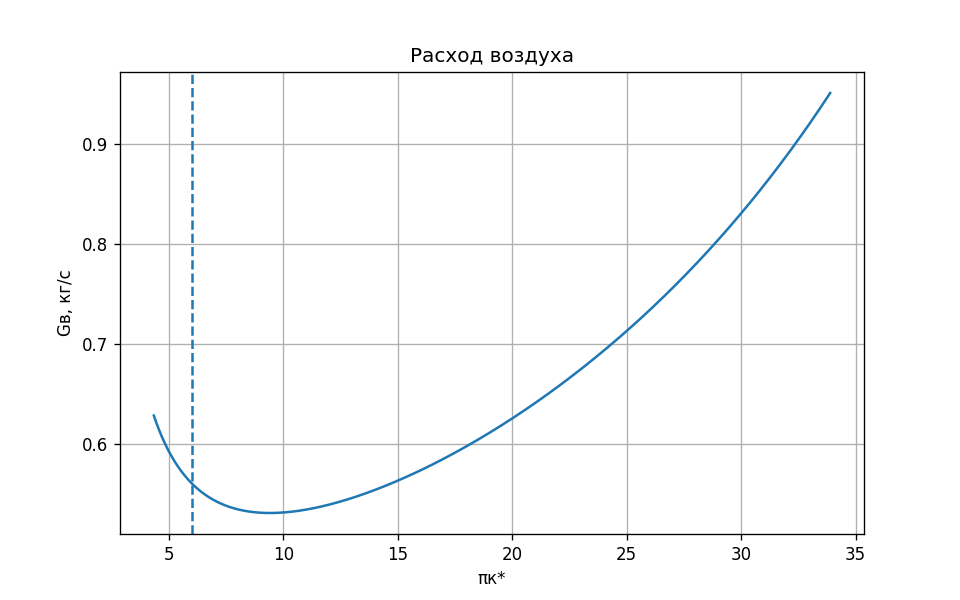

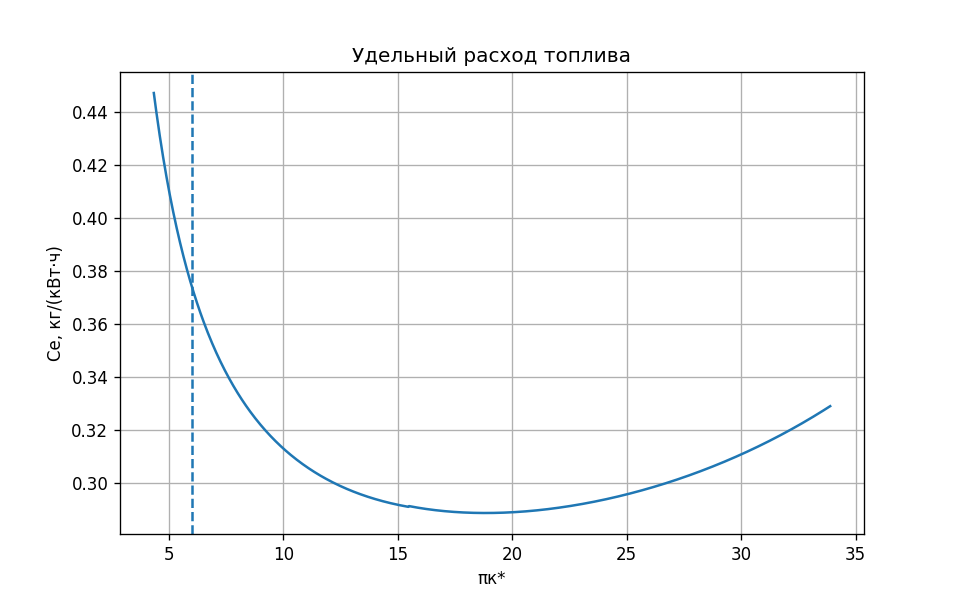

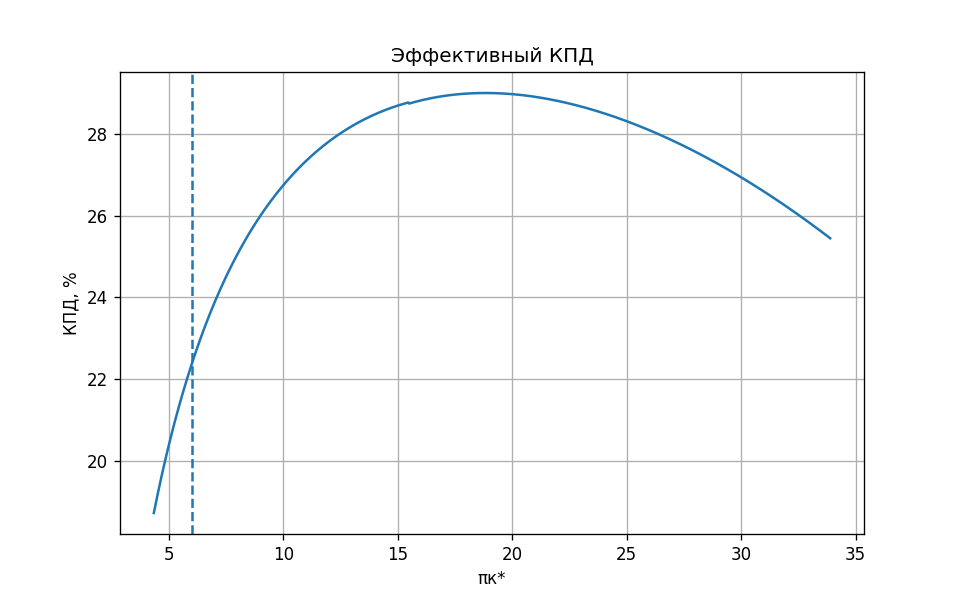

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['G_air'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Gв, кг/с')
plt.title('Расход воздуха')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], variants['Ce_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('Ce, кг/(кВт·ч)')
plt.title('Удельный расход топлива')
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(variants['pi_k'], 100*variants['eta_shaft'])
plt.axvline(s['pi_k'], linestyle='--')
plt.xlabel('πк*')
plt.ylabel('КПД, %')
plt.title('Эффективный КПД')
plt.grid()
plt.show()

# Проектирование турбины

Предварительный расчёт по заданной удельной работе для ТК и СТ при выбранной точке цикла. Принятый закон проточной части $D_{вт}=\mathrm{const}$ применяется при построении меридионального сечения на следующем этапе.

[Методичка](https://chatgpt.com/library?file_id=libfile_f536fb3e60c881918ed5fdff9ab72d0f&account_id=personal) — Михальцев В. Е., Моляков В. Д. «Теория и проектирование газовой турбины», ч. 1, МГТУ им. Н. Э. Баумана, 2006. Номера страниц ниже приведены по изданию.

## 1. Исходные данные из цикла

ТК — турбина компрессора. СТ — свободная силовая турбина. Входные полные параметры СТ на этом этапе берём из цикла за ТК. Состав газа задают $\alpha$ и $R_g$. Расход один для обеих турбин в принятом варианте без дополнительного подвода охлаждающего воздуха между ними.

$$L_{\mathrm{ТК,треб}}=\frac{N_k}{G_g\eta_{m,\mathrm{ТК}}},\qquad
L_{\mathrm{СТ,треб}}=\frac{N_e}{G_g\eta_{m,\mathrm{СТ}}\eta_r}.$$

Удельные работы уже посчитаны в цикле. Проверяем их по балансам валов. Мощность выражена в кВт, удельная работа в кДж/кг, расход в кг/с.

**Источник.** Михальцев, Моляков, «Теория и проектирование газовой турбины», ч. 1, с. 84, § 9, «Задание» и с. 93, п. 152–153.

In [15]:
design_cycle = s
pi_k_design = design_cycle['pi_k']
G_gas_design = design_cycle['G_gas']
alpha_design = design_cycle['alpha']

L_tk_required = design_cycle['L_gg']
L_st_required = design_cycle['L_pt']
assert math.isclose(G_gas_design * L_tk_required * eta_m_gg, design_cycle['N_compressor'])
assert math.isclose(G_gas_design * L_st_required * eta_m_pt * eta_red, power_kw)

stage_inputs = pd.DataFrame([
    ['ТК', design_cycle['Tg'], design_cycle['pg'], L_tk_required],
    ['СТ', design_cycle['T4'], design_cycle['p4'], L_st_required]
], columns=['Турбина', 'T0*, К', 'p0*, кПа', 'L треб., кДж/кг']).set_index('Турбина')
stage_inputs['G газа, кг/с'] = G_gas_design
stage_inputs['Коэффициент избытка воздуха'] = alpha_design
stage_inputs['R газа, кДж/(кг·К)'] = R_gas

print(f'Расчётная точка: πк = {pi_k_design:g}, мощность на валу {power_kw:.3f} кВт')
display(stage_inputs)

Расчётная точка: πк = 6, мощность на валу 110.325 кВт


,"T0*, К","p0*, кПа","L треб., кДж/кг","G газа, кг/с",Коэффициент избытка воздуха,"R газа, кДж/(кг·К)"
Турбина,,,,,,
ТК,1250.0000,577.7291,233.3292,0.5687,3.3252,0.2880
СТ,1057.3630,264.2799,199.9632,0.5687,3.3252,0.2880


## 2. Предварительный теплоперепад, выходная площадь и обороты

Выбираем начальные $\eta_{л,оц}$ и $c_{2a,оц}$. Как и в п. 15, в оценке выходной кинетической энергии используем осевую составляющую скорости.

$$H_{0,оц}=\frac{L_{треб}+c_{2a,оц}^2/2000}{\eta_{л,оц}},\qquad
T_{2,оц}=T_0^*-\frac{\eta_{л,оц}H_{0,оц}}{c_p},$$
$$p_{2,оц}=p_0^*\left(1-\frac{H_{0,оц}}{c_p T_0^*}\right)^{k/(k-1)},\qquad
v_{2,оц}=\frac{R_gT_{2,оц}}{p_{2,оц}},\qquad A_{2,оц}=\frac{G_gv_{2,оц}}{c_{2a,оц}},$$
$$n_{max,оц}=\sqrt{\frac{\sigma_{л,доп}}{k_n A_{2,оц}}},\qquad \sigma_{л,оц}=k_n n^2 A_{2,оц}.$$

Оценочные значения $\eta_{л,оц}=0{,}90$, $c_{2a,оц}=200$ м/с для ТК и $250$ м/с для СТ приняты для первого приближения. Обороты округлены до 78 000 и 70 000 об/мин соответственно. $k_n=6{,}8\cdot10^{-6}$ применяем с площадью в м², оборотами в об/мин и напряжением в МПа. $\sigma_{л,доп}=200$ МПа — предварительное допущение до выбора материала и ресурса. Для свойств используем среднюю температуру и принятую в цикле функцию `process_properties`.

**Источник.** Михальцев, Моляков, «Теория и проектирование газовой турбины», ч. 1, с. 55–56, формула (63) и коэффициент $k_n$, с. 85–86, п. 13–25.

In [16]:
eta_blade_est = 0.90
c2a_est = {'ТК': 200.0, 'СТ': 250.0}  # м/с
n_selected = {'ТК': 78000.0, 'СТ': 70000.0}  # об/мин
kn = 6.8e-6
sigma_limit = 200.0  # МПа

preliminary_rows = []
for name, row in stage_inputs.iterrows():
    T0 = row['T0*, К']
    p0 = row['p0*, кПа']
    L_required = row['L треб., кДж/кг']
    ca = c2a_est[name]
    n = n_selected[name]
    H0 = (L_required + ca**2 / 2000) / eta_blade_est

    # Уточнение T2 с теплоёмкостью при средней температуре.
    def temperature_residual(T2):
        cp, _ = process_properties(T0, T2, alpha_design, R_gas)
        return cp * (T0 - T2) - eta_blade_est * H0

    if temperature_residual(100.0) <= 0:
        raise ValueError(f'{name}: не найден диапазон статической температуры')
    T2 = bisect(temperature_residual, 100.0, T0)
    cp, k = process_properties(T0, T2, alpha_design, R_gas)
    pressure_base = 1 - H0 / (cp * T0)
    if pressure_base <= 0:
        raise ValueError(f'{name}: теплоперепад слишком велик для принятых исходных данных')
    p2 = p0 * pressure_base**(k / (k - 1))
    v2 = R_gas * T2 / p2
    A2 = G_gas_design * v2 / ca
    n_max = math.sqrt(sigma_limit / (kn * A2))

    preliminary_rows.append({
        'Турбина': name, 'H0 оценка, кДж/кг': H0, 'cp, кДж/(кг·К)': cp, 'k': k,
        'c2a оценка, м/с': ca, 'T2 оценка, К': T2, 'p2 оценка, кПа': p2,
        'v2 оценка, м³/кг': v2, 'A2 оценка, см²': A2 * 1e4,
        'n, об/мин': n, 'n_max оценка, об/мин': n_max,
        'Напряжение, МПа': kn * n**2 * A2, 'n ниже n_max': n < n_max
    })

preliminary = pd.DataFrame(preliminary_rows).set_index('Турбина')
display(preliminary)

,"H0 оценка, кДж/кг","cp, кДж/(кг·К)",k,"c2a оценка, м/с","T2 оценка, К","p2 оценка, кПа","v2 оценка, м³/кг","A2 оценка, см²","n, об/мин","n_max оценка, об/мин","Напряжение, МПа",n ниже n_max
Турбина,,,,,,,,,,,,
ТК,281.4769,1.2097,1.3125,200.0000,1040.5867,243.2134,1.2322,35.0360,78000.0000,91622.6871,144.9483,True
СТ,256.9036,1.1722,1.3257,250.0000,860.1109,102.6787,2.4125,54.8767,70000.0000,73209.3190,182.8493,True


## 3. Реактивность, оптимальная окружная скорость и средний диаметр

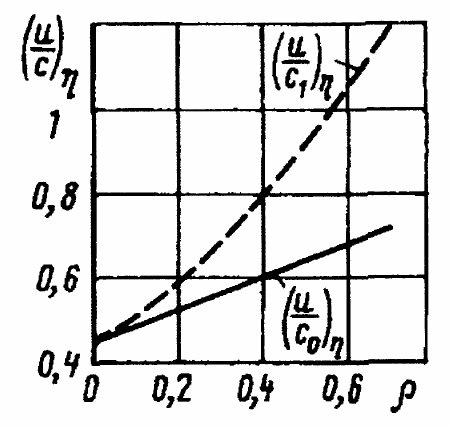

Берём четыре приближённые точки с нижней сплошной кривой $(u/c_0)_{опт}$ на рис. 18. Аппроксимируем их полиномом первой степени. Все расчётные значения $\rho$ лежат в интервале оцифрованных точек.

$$c_0=\sqrt{2000H_{0,оц}},\qquad u_{опт}=c_0\left(\frac{u}{c_0}\right)_{опт}(\rho),\qquad
D_{ср,2}=\frac{60u_{опт}}{\pi n},\qquad l_2=\frac{A_{2,оц}}{\pi D_{ср,2}}.$$

На с. 58 даны ориентировочные пары $(\rho,l/D)$. Между ними используем линейную интерполяцию. При выбранных оборотах методом бисекции ищем $\rho$, при котором $l_2/D_{ср,2}$ совпадает с интерполированным ориентиром. Это способ численного согласования для первого приближения. После расчёта треугольников скоростей нужно отдельно проверить реактивность у корня и уточнить параметры ступени.

**Источник.** Михальцев, Моляков, «Теория и проектирование газовой турбины», ч. 1, с. 52–53, рис. 18, с. 58–59, § 6.2 и с. 86, п. 26–32.

In [17]:
# Приближённое считывание нижней кривой рис. 18.
rho_fig18 = np.array([0.0, 0.2, 0.4, 0.6])
u_c0_fig18 = np.array([0.450, 0.525, 0.600, 0.675])
u_c0_fit = np.polyfit(rho_fig18, u_c0_fig18, 1)
print(f'Аппроксимация рис. 18: (u/c0)опт ≈ {u_c0_fit[1]:.3f} + {u_c0_fit[0]:.3f}·ρ')
display(pd.DataFrame({'ρ': rho_fig18, '(u/c0)опт, по рисунку': u_c0_fig18}))

# Таблица ориентиров со с. 58. Степень реактивности отсортирована по возрастанию.
rho_ref = np.array([0.2, 0.3, 0.4, 0.5])
lD_ref = np.array([1/9, 1/6, 1/4, 1/3])

geometry_rows = []
for name, row in preliminary.iterrows():
    if not row['n ниже n_max']:
        raise ValueError(f'{name}: снизьте выбранные обороты до оценки n_max')
    c0 = math.sqrt(2000 * row['H0 оценка, кДж/кг'])
    n = row['n, об/мин']
    A2 = row['A2 оценка, см²'] / 1e4

    def lD_residual(rho):
        u_opt = c0 * np.polyval(u_c0_fit, rho)
        D2 = 60 * u_opt / (math.pi * n)
        return A2 / (math.pi * D2**2) - np.interp(rho, rho_ref, lD_ref)

    if lD_residual(rho_ref[0]) * lD_residual(rho_ref[-1]) > 0:
        raise ValueError(f'{name}: при выбранных оборотах нет пересечения в диапазоне ρ=0,2–0,5')
    rho = bisect(lD_residual, rho_ref[0], rho_ref[-1])
    u_c0_opt = np.polyval(u_c0_fit, rho)
    u_opt = c0 * u_c0_opt
    D2 = 60 * u_opt / (math.pi * n)
    l2 = A2 / (math.pi * D2)
    geometry_rows.append({
        'Турбина': name, 'ρ предварительная': rho, 'c0, м/с': c0,
        '(u/c0) оптимальное': u_c0_opt, 'u оптимальная, м/с': u_opt,
        'D средний за РК, мм': D2 * 1000, 'l рабочей лопатки, мм': l2 * 1000,
        'l/D расчётное': l2 / D2, 'l/D по ориентиру': np.interp(rho, rho_ref, lD_ref)
    })

geometry = pd.DataFrame(geometry_rows).set_index('Турбина')
display(geometry)

Аппроксимация рис. 18: (u/c0)опт ≈ 0.450 + 0.375·ρ


,ρ,"(u/c0)опт, по рисунку"
0,0.0000,0.4500
1,0.2000,0.5250
2,0.4000,0.6000
3,0.6000,0.6750


,ρ предварительная,"c0, м/с",(u/c0) оптимальное,"u оптимальная, м/с","D средний за РК, мм","l рабочей лопатки, мм",l/D расчётное,l/D по ориентиру
Турбина,,,,,,,,
ТК,0.2121,750.3025,0.5295,397.3151,97.2841,11.4637,0.1178,0.1178
СТ,0.2704,716.8035,0.5514,395.2410,107.8364,16.1984,0.1502,0.1502


Полученные $D_{ср,2}$ и $l_2$ служат исходными размерами для пункта 4, в котором определяется втулочный диаметр и строится меридиональное сечение каждой турбины.